# Задание 3.5

**(Движение математического маятника)** Исследовать движение математического маятника — точечной массы на невесомом нерастяжимом стержне в поле тяжести.

1) В ноутбуке (файл Jupyter Notebook) в разметке Markdown (LaTeX) привести подробное аналитическое решение (вывод уравнения движения, анализ решений);
2) Привести статическую картинку в формате png (pdf) решения задачи (код на Jupyter Notebook, который создаёт рисунок);
3) Используя инструментарий Jupyter Notebook, привести анимацию данного решения.

**Детализация задания.** *Цель:* исследовать и визуализировать движение математического маятника, включая линейные и нелинейные режимы.

- **Аналитическое решение:** вывести уравнение движения из второго закона Ньютона; проанализировать линеаризованное решение для малых углов; исследовать нелинейные эффекты и точное решение через эллиптические интегралы; построить фазовый портрет системы.
- **Статическая визуализация:** графики углового отклонения для различных начальных условий; фазовый портрет с выделением различных режимов движения; зависимость периода от амплитуды; сепаратриса и области колебаний/вращений.
- **Анимация:** `FuncAnimation`; движение маятника в конфигурационном пространстве; одновременная визуализация на фазовой плоскости; переход от гармонических к нелинейным колебаниям.

## Теория

**1. Уравнение движения.** Масса $m$ закреплена на невесомом стержне длины $l$, $\theta$ — угол отклонения от нижней вертикали. На массу действуют сила тяжести $m\vec g$ и натяжение стержня $\vec N$, направленное вдоль стержня. Проецируем второй закон Ньютона $m\vec a=m\vec g+\vec N$ на касательную к окружности, по которой движется точка. Натяжение при этом исключается, а касательное ускорение равно $l\ddot\theta$:

$$
ml\ddot\theta=-mg\sin\theta\qquad\Longrightarrow\qquad \boxed{\ \ddot\theta+\omega_0^2\sin\theta=0,\qquad \omega_0^2=\frac gl\ }
$$

Проекция на нормаль даёт натяжение $N=m\big(l\dot\theta^2+g\cos\theta\big)$.

**2. Линеаризация (малые углы).** При $|\theta|\ll1$ имеем $\sin\theta\approx\theta$, и уравнение становится уравнением гармонического осциллятора:

$$
\ddot\theta+\omega_0^2\theta=0\ \Longrightarrow\ \theta(t)=\theta_0\cos\omega_0t+\frac{\dot\theta_0}{\omega_0}\sin\omega_0t,\qquad T_0=2\pi\sqrt{\frac lg}.
$$

Период не зависит от амплитуды (изохронность малых колебаний).

**3. Интеграл энергии и фазовый портрет.** Умножая уравнение на $\dot\theta$ и интегрируя, получаем

$$
E=\frac{\dot\theta^2}{2}-\omega_0^2\cos\theta=\mathrm{const}\qquad\Longrightarrow\qquad \dot\theta=\pm\sqrt{2\,(E+\omega_0^2\cos\theta)} .
$$

Фазовые траектории — линии уровня $E$ на плоскости $(\theta,\dot\theta)$, причём $\theta$ определено с точностью до $2\pi$ (фазовое пространство — цилиндр).
- Положения равновесия: $(0,0)$ — **центр** (устойчивое нижнее положение); $(\pm\pi,0)$ — **седло** (неустойчивое верхнее).
- $-\omega_0^2<E<\omega_0^2$ — замкнутые кривые вокруг центра, **колебания**.
- $E=\omega_0^2$ — **сепаратриса** $\dot\theta=\pm2\omega_0\cos\frac\theta2$: маятник за бесконечное время асимптотически приходит в верхнее положение, $\theta(t)=4\operatorname{arctg}e^{\omega_0t}-\pi$.
- $E>\omega_0^2$ — незамкнутые на плоскости (замкнутые на цилиндре) кривые, **вращения**.

**4. Точное решение и период через эллиптические интегралы.** Пусть маятник отпущен без начальной скорости с угла $\theta_0$. Тогда $E=-\omega_0^2\cos\theta_0$, и

$$
\dot\theta^2=2\omega_0^2(\cos\theta-\cos\theta_0)=4\omega_0^2\left(k^2-\sin^2\frac\theta2\right),\qquad k=\sin\frac{\theta_0}{2}.
$$

Подстановка $\sin\frac\theta2=k\sin\psi$ даёт $d\theta=\dfrac{2k\cos\psi\,d\psi}{\sqrt{1-k^2\sin^2\psi}}$, и четверть периода выражается через **полный эллиптический интеграл первого рода**:

$$
T=4\int_0^{\theta_0}\frac{d\theta}{\dot\theta}=\frac4{\omega_0}\int_0^{\pi/2}\frac{d\psi}{\sqrt{1-k^2\sin^2\psi}}=\frac{4K(k)}{\omega_0},
\qquad \frac{T}{T_0}=\frac2\pi K(k)=1+\frac{\theta_0^2}{16}+\frac{11\,\theta_0^4}{3072}+\dots
$$

При $\theta_0\to\pi$ ($k\to1$) $K(k)\sim\ln\dfrac{4}{\sqrt{1-k^2}}\to\infty$: период неограниченно растёт. Обращение интеграла даёт закон движения через эллиптический синус Якоби:

$$
\sin\frac{\theta(t)}2=k\,\operatorname{sn}\big(\omega_0t+K(k),\,k\big)
\qquad(\theta(0)=\theta_0,\ \dot\theta(0)=0).
$$

Для вращений ($E>\omega_0^2$) с $\varkappa^2=\dfrac{E+\omega_0^2}{2\omega_0^2}>1$ период полного оборота равен $T_{\rm rot}=\dfrac{2}{\omega_0\varkappa}K\!\left(\dfrac1\varkappa\right)$.

**5. Нелинейные эффекты.** С ростом амплитуды период увеличивается, и большие колебания отстают от гармонических. Форма $\theta(t)$ отличается от косинусоиды: около крайних точек маятник «задерживается», график становится более «прямоугольным». На фазовой плоскости овалы вытягиваются в сторону сепаратрисы.

**Что делаем в коде.** Уравнение решаем численно (`scipy.integrate.solve_ivp`) и сравниваем с точной формулой через `scipy.special.ellipj`/`ellipk` и с линейным решением. Период измеряем по численному решению и сравниваем с $\frac{2}{\pi}K(k)$. Строим фазовый портрет с сепаратрисой и областями колебаний и вращений. В анимации одновременно движутся маятники с амплитудами $15^\circ$, $90^\circ$, $160^\circ$ и вращающийся маятник; пунктиром показаны «линейные двойники». Справа — их точки на фазовой плоскости. Анимация встроена через `to_jshtml()` (проигрыватель с паузой и шагом).

T0 = 2π√(l/g) = 2.00607 с
θ0 =  10°:  max|θ_числ − θ_эллипт| = 7.4e-12,  T/T0: численно 1.001907, (2/π)K(k) = 1.001907, 1+θ0²/16 = 1.0019
θ0 =  60°:  max|θ_числ − θ_эллипт| = 6.8e-11,  T/T0: численно 1.073182, (2/π)K(k) = 1.073182, 1+θ0²/16 = 1.0685
θ0 = 120°:  max|θ_числ − θ_эллипт| = 2.7e-10,  T/T0: численно 1.372881, (2/π)K(k) = 1.372881, 1+θ0²/16 = 1.2742
θ0 = 170°:  max|θ_числ − θ_эллипт| = 2.9e-09,  T/T0: численно 2.439363, (2/π)K(k) = 2.439363, 1+θ0²/16 = 1.5502


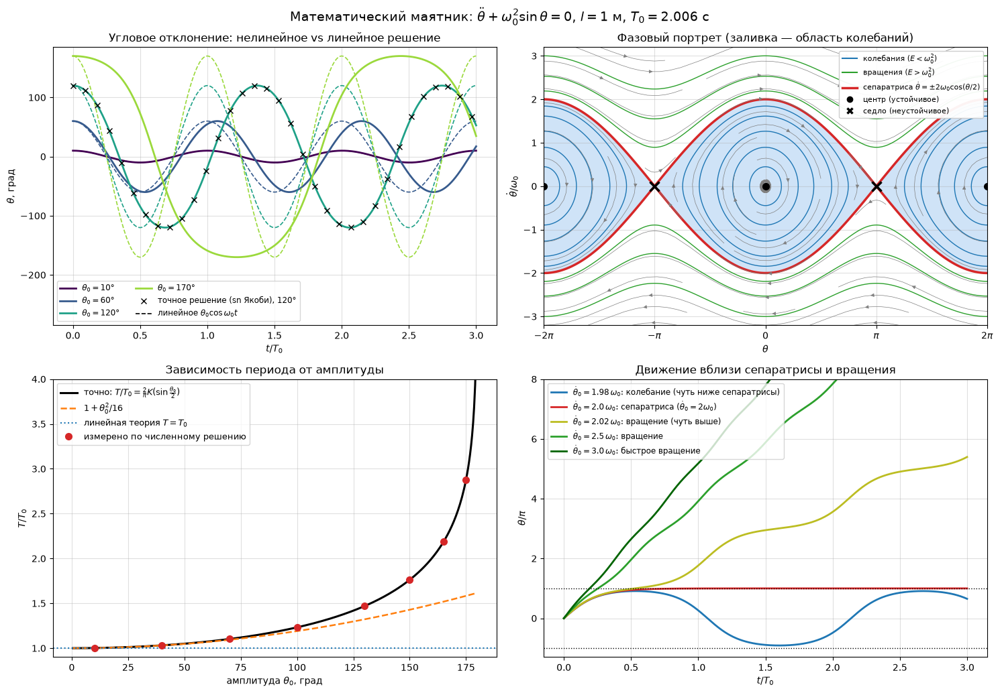

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.integrate import solve_ivp
from scipy.special import ellipk, ellipj
from IPython.display import HTML, display

g, l = 9.81, 1.0
w0 = np.sqrt(g/l)                 # собственная частота малых колебаний
T0 = 2*np.pi/w0                   # период малых колебаний


def rhs(t, u):
    """θ'' = -ω0² sin θ."""
    return [u[1], -w0**2*np.sin(u[0])]


def simulate(th0, dth0, t):
    return solve_ivp(rhs, [t[0], t[-1]], [th0, dth0], t_eval=t, rtol=1e-11, atol=1e-12).y


def theta_exact(t, th0):
    """Точное решение: sin(θ/2) = k·sn(ω0 t + K(k), k), k = sin(θ0/2) (в scipy параметр m = k²)."""
    m = np.sin(th0/2)**2
    sn = ellipj(w0*t + ellipk(m), m)[0]
    return 2*np.arcsin(np.sqrt(m)*sn)


def period_ratio(th0):
    """T/T0 = (2/π)·K(k)."""
    return 2/np.pi*ellipk(np.sin(th0/2)**2)


# ---------- Проверка точного решения и формулы периода ----------
t = np.linspace(0, 3*T0, 2001)
print(f"T0 = 2π√(l/g) = {T0:.5f} с")
for deg in (10, 60, 120, 170):
    th0 = np.radians(deg)
    num = simulate(th0, 0, t)[0]
    # период по численному решению: момент, когда θ' впервые снова = 0 (точка -θ0), — это T/2
    ev = lambda t_, u: u[1]
    ev.direction = 1
    t_half = solve_ivp(rhs, [0, 10*T0], [th0, 0], events=ev, rtol=1e-12, atol=1e-12).t_events[0][0]
    print(f"θ0 = {deg:3d}°:  max|θ_числ − θ_эллипт| = {np.max(np.abs(num - theta_exact(t, th0))):.1e},  "
          f"T/T0: численно {2*t_half/T0:.6f}, (2/π)K(k) = {period_ratio(th0):.6f}, 1+θ0²/16 = {1 + th0**2/16:.4f}")

# ---------- Статический рисунок ----------
fig, axs = plt.subplots(2, 2, figsize=(15, 10.5))
amps = [10, 60, 120, 170]
cols = plt.cm.viridis(np.linspace(0, 0.85, len(amps)))

# (а) θ(t): нелинейное решение (сплошные) и линейное приближение (штрих)
ax = axs[0, 0]
for deg, col in zip(amps, cols):
    th0 = np.radians(deg)
    ax.plot(t/T0, np.degrees(simulate(th0, 0, t)[0]), color=col, lw=2, label=f"$\\theta_0={deg}°$")
    ax.plot(t/T0, np.degrees(th0*np.cos(w0*t)), "--", color=col, lw=1.2)
te = t[::60]
ax.plot(te/T0, np.degrees(theta_exact(te, np.radians(120))), "kx", ms=6, label="точное решение (sn Якоби), $120°$")
ax.plot([], [], "k--", lw=1.2, label="линейное $\\theta_0\\cos\\omega_0t$")
ax.set(xlabel="$t/T_0$", ylabel="$\\theta$, град", title="Угловое отклонение: нелинейное vs линейное решение", ylim=(-285, 185))
ax.legend(fontsize=8.5, loc="lower left", ncol=2)

# (б) фазовый портрет: уровни энергии, сепаратриса, области колебаний и вращений
ax = axs[0, 1]
TH, W = np.meshgrid(np.linspace(-2*np.pi, 2*np.pi, 600), np.linspace(-3.2, 3.2, 400))   # W = θ'/ω0
E = W**2/2 - np.cos(TH)                                     # энергия в единицах ω0²; сепаратриса E = 1
ax.contourf(TH, W, E, levels=[-1.01, 1], colors=["#cfe3f7"])
ax.contour(TH, W, E, levels=[-0.9, -0.6, -0.2, 0.3, 0.7], colors="tab:blue", linewidths=1, negative_linestyles="solid")
ax.contour(TH, W, E, levels=[1.4, 2.2, 3.5], colors="tab:green", linewidths=1)
ax.contour(TH, W, E, levels=[1.0], colors="tab:red", linewidths=2.5)
ax.streamplot(TH, W, W, -np.sin(TH), color="gray", density=0.7, linewidth=0.5, arrowsize=0.8)
ax.plot([-2*np.pi, 0, 2*np.pi], [0, 0, 0], "ko", ms=7)
ax.plot([-np.pi, np.pi], [0, 0], "kx", ms=10, mew=2.5)
for lab, st in [("колебания ($E<\\omega_0^2$)", dict(color="tab:blue")), ("вращения ($E>\\omega_0^2$)", dict(color="tab:green")),
                ("сепаратриса $\\dot\\theta=\\pm2\\omega_0\\cos(\\theta/2)$", dict(color="tab:red", lw=2.5))]:
    ax.plot([], [], label=lab, **st)
ax.plot([], [], "ko", label="центр (устойчивое)"); ax.plot([], [], "kx", mew=2.5, label="седло (неустойчивое)")
ax.set_xticks(np.arange(-2, 3)*np.pi, ["$-2\\pi$", "$-\\pi$", "0", "$\\pi$", "$2\\pi$"])
ax.set(xlabel="$\\theta$", ylabel="$\\dot\\theta/\\omega_0$", title="Фазовый портрет (заливка — область колебаний)",
       xlim=(-2*np.pi, 2*np.pi), ylim=(-3.2, 3.2))
ax.legend(fontsize=8, loc="upper right", framealpha=0.95)

# (в) зависимость периода от амплитуды
ax = axs[1, 0]
a_deg = np.linspace(0.5, 179.5, 400)
ax.plot(a_deg, period_ratio(np.radians(a_deg)), "k-", lw=2.2, label="точно: $T/T_0=\\frac{2}{\\pi}K(\\sin\\frac{\\theta_0}{2})$")
ax.plot(a_deg, 1 + np.radians(a_deg)**2/16, "--", color="tab:orange", lw=1.8, label="$1+\\theta_0^2/16$")
ax.axhline(1, color="tab:blue", lw=1.5, ls=":", label="линейная теория $T=T_0$")
pts = np.array([10, 40, 70, 100, 130, 150, 165, 175])
meas = []
for deg in pts:
    ev = lambda t_, u: u[1]
    ev.direction = 1
    meas.append(2*solve_ivp(rhs, [0, 20*T0], [np.radians(deg), 0], events=ev, rtol=1e-12, atol=1e-12).t_events[0][0]/T0)
ax.plot(pts, meas, "o", color="tab:red", ms=7, label="измерено по численному решению")
ax.set(xlabel="амплитуда $\\theta_0$, град", ylabel="$T/T_0$", title="Зависимость периода от амплитуды", ylim=(0.9, 4))
ax.legend(fontsize=9, loc="upper left")

# (г) режимы около сепаратрисы: колебание, асимптотическое движение, вращения (старт из θ = 0)
ax = axs[1, 1]
t2 = np.linspace(0, 3*T0, 2000)
for v, col, lab in [(1.98, "tab:blue", "колебание (чуть ниже сепаратрисы)"), (2.0, "tab:red", "сепаратриса ($\\dot\\theta_0=2\\omega_0$)"),
                    (2.02, "tab:olive", "вращение (чуть выше)"), (2.5, "tab:green", "вращение"), (3.0, "darkgreen", "быстрое вращение")]:
    ax.plot(t2/T0, simulate(0.0, v*w0, t2)[0]/np.pi, color=col, lw=2, label=f"$\\dot\\theta_0={v}\\,\\omega_0$: {lab}")
ax.axhline(1, color="k", ls=":", lw=1); ax.axhline(-1, color="k", ls=":", lw=1)
ax.set(xlabel="$t/T_0$", ylabel="$\\theta/\\pi$", title="Движение вблизи сепаратрисы и вращения", ylim=(-1.3, 8))
ax.legend(fontsize=8.5, loc="upper left")

for ax in axs.flat:
    ax.grid(alpha=0.4)
fig.suptitle(f"Математический маятник: $\\ddot\\theta+\\omega_0^2\\sin\\theta=0$, $l={l:g}$ м, $T_0={T0:.3f}$ с", fontsize=14)
fig.tight_layout()
fig.savefig("3.5.png", dpi=150)       # сохраняем статическую картинку
plt.show()

# ---------- Анимация ----------
cases = [(15, 0.0, "tab:blue"), (90, 0.0, "tab:orange"), (160, 0.0, "tab:red"), (0, 2.3, "tab:green")]   # (θ0°, θ'0/ω0, цвет)
t_end = 2*period_ratio(np.radians(160))*T0                    # два периода самого медленного маятника
n_frames = 120
tf = np.linspace(0, t_end, n_frames)
sols = [simulate(np.radians(d), v*w0, tf) for d, v, _ in cases]
pivots = np.array([0.0, 2.6, 5.2, 7.8])

fig, (ax, axp) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=58, gridspec_kw=dict(width_ratios=[1.55, 1]))
ax.set(xlim=(-1.3, 9.1), ylim=(-1.3, 1.85), aspect="equal", xticks=[], yticks=[],
       title="Маятники (пунктир — линейное приближение $\\theta_0\\cos\\omega_0 t$)")
rods, bobs, ghosts, labels = [], [], [], []
for (d, v, col), px in zip(cases, pivots):
    ax.plot(px, 0, "ks", ms=6)
    ax.add_patch(plt.Circle((px, 0), l, fill=False, ls=":", color="lightgray"))
    ghosts.append(ax.plot([], [], "--o", color="gray", mfc="none", ms=12, lw=1)[0] if v == 0 else None)
    rods.append(ax.plot([], [], "-", color="k", lw=2)[0])
    bobs.append(ax.plot([], [], "o", color=col, mec="k", ms=14)[0])
    if v == 0:
        txt = f"$\\theta_0={d}°$\n$T/T_0={period_ratio(np.radians(d)):.3f}$"
    else:
        txt = f"вращение\n$\\dot\\theta_0={v}\\omega_0$"
    ax.text(px, 1.25, txt, ha="center", va="bottom", fontsize=10, color=col)
clock = ax.text(0.01, 0.02, "", transform=ax.transAxes, family="monospace", fontsize=10)

# фазовая плоскость (θ приводим к (-π, π])
THp, Wp = np.meshgrid(np.linspace(-np.pi, np.pi, 300), np.linspace(-3, 3, 200))
Ep = Wp**2/2 - np.cos(THp)
axp.contourf(THp, Wp, Ep, levels=[-1.01, 1], colors=["#e3eefa"])
axp.contour(THp, Wp, Ep, levels=[-0.9, -0.5, 0, 0.5, 1.5, 2.5], colors="lightgray", linewidths=0.8, negative_linestyles="solid")
axp.contour(THp, Wp, Ep, levels=[1.0], colors="tab:red", linewidths=1.5, linestyles="--")
axp.plot([], [], "--", color="tab:red", label="сепаратриса")
trails, dots = [], []
for d, v, col in cases:
    trails.append(axp.plot([], [], color=col, lw=2)[0])
    dots.append(axp.plot([], [], "o", color=col, mec="k", ms=9)[0])
axp.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi], ["$-\\pi$", "$-\\pi/2$", "0", "$\\pi/2$", "$\\pi$"])
axp.set(xlim=(-np.pi, np.pi), ylim=(-3, 3), xlabel="$\\theta$", ylabel="$\\dot\\theta/\\omega_0$", title="Фазовая плоскость")
axp.grid(alpha=0.3); axp.legend(loc="upper right", fontsize=9)


def wrap(a):
    return (a + np.pi) % (2*np.pi) - np.pi


def update(i):
    t = tf[i]
    for k, ((d, v, col), px, (th, w)) in enumerate(zip(cases, pivots, sols)):
        q = th[i]
        bx, by = px + l*np.sin(q), -l*np.cos(q)                     # положение груза
        rods[k].set_data([px, bx], [0, by])
        bobs[k].set_data([bx], [by])
        if ghosts[k] is not None:                                   # линейный «двойник»
            ql = np.radians(d)*np.cos(w0*t)
            ghosts[k].set_data([px, px + l*np.sin(ql)], [0, -l*np.cos(ql)])
        # след на фазовой плоскости; разрываем линию при переходе через ±π
        j0 = max(0, i - 50)
        thw, ww = wrap(th[j0:i+1]), w[j0:i+1]/w0
        jump = np.r_[False, np.abs(np.diff(thw)) > np.pi]
        thw, ww = thw.astype(float).copy(), ww.copy()
        thw[jump] = np.nan
        trails[k].set_data(thw, ww)
        dots[k].set_data([wrap(q)], [w[i]/w0])
    clock.set_text(f"t = {t:5.2f} с = {t/T0:4.2f} T0")
    return [*rods, *bobs, *[g_ for g_ in ghosts if g_ is not None], *trails, *dots, clock]


anim = FuncAnimation(fig, update, frames=n_frames, interval=50, blit=True)
fig.tight_layout()
plt.close(fig)
display(HTML(anim.to_jshtml(default_mode="loop")))   # проигрыватель: пуск/пауза, шаг, скорость